# Visualización del panel mediante reducción de dimensionalidad

Comparamos **PCA, SVD truncada, Isomap y t-SNE**. Las mismas 2,000 personas y el mismo
preprocesamiento se usan en los cuatro mapas. Elegimos una primera observación por cliente
para evitar que los perfiles repetidos y los sobrevivientes de larga duración dominen la geometría.
El color del objetivo significa **conversión en ese primer mes observado**, no conversión eventual.

Después proyectamos trayectorias cliente-mes con PCA. Es exploración descriptiva de train,
no entrenamiento de un predictor ni evaluación fuera de tiempo. No se utiliza test.

In [2]:
# Configuración; el notebook se puede ejecutar desde esta carpeta o desde la raíz del proyecto.
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import BoundaryNorm
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE, Isomap, trustworthiness
from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=4)
SEED, SAMPLE_SIZE = 42, 2000
ROOT = Path.cwd() if (Path.cwd() / 'train.csv').exists() else Path.cwd().parent
OUT = ROOT / 'visualizacion_dimensional'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
train = pd.read_csv(ROOT / 'train.csv').sort_values(['id_cliente', 'mes'])
first = train.drop_duplicates('id_cliente', keep='first').copy()
sample = first.sample(n=min(SAMPLE_SIZE, len(first)), random_state=SEED).reset_index(drop=True)
display(pd.DataFrame({
    'conjunto': ['Train cliente-mes', 'Primera observación por cliente', 'Muestra común para mapas'],
    'filas': [len(train), len(first), len(sample)],
    'tasa_conversion': [train.objetivo.mean(), first.objetivo.mean(), sample.objetivo.mean()],
}))

,conjunto,filas,tasa_conversion
0,Train cliente-mes,110100,0.150472
1,Primera observación por cliente,24628,0.159696
2,Muestra común para mapas,2000,0.157000


## Preparación y distancias

Excluimos ID, mes y objetivo de la matriz. Estandarizamos las numéricas, conservamos booleanos
como 0/1 y aplicamos one-hot a categorías. No estandarizamos cada dummy: hacerlo amplificaría
categorías raras. La geometría depende de esta elección; no es una distancia financiera universal.
Se ajusta el preprocesamiento a las primeras observaciones de train, sin usar las etiquetas.
Banda de riesgo **sí es un predictor**: separación al colorear por banda no es evidencia de predicción.

In [3]:
features = [c for c in train if c not in ['id_cliente', 'mes', 'objetivo']]
categorical = first[features].select_dtypes(include='object').columns.tolist()
boolean = first[features].select_dtypes(include='bool').columns.tolist()
numeric = [c for c in features if c not in categorical + boolean]
prep = ColumnTransformer([
    ('num', StandardScaler(), numeric),
    ('bool', 'passthrough', boolean),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
], verbose_feature_names_out=False)
X_population = np.asarray(prep.fit_transform(first[features]), dtype=float)
X = np.asarray(prep.transform(sample[features]), dtype=float)
assert {'id_cliente', 'mes', 'objetivo'}.isdisjoint(features)
assert np.isfinite(X).all() and sample.id_cliente.is_unique
print(f'{len(features)} predictores originales → {X.shape[1]} columnas transformadas; {len(X):,} puntos por mapa.')

22 predictores originales → 39 columnas transformadas; 2,000 puntos por mapa.


## Cuatro mapas de las mismas personas

**PCA:** proyección lineal centrada que maximiza varianza.
**SVD truncada:** proyección lineal sin centrar; con one-hot puede dar más peso a la composición media.
**Isomap:** aproximación no lineal que usa distancias sobre un grafo de vecinos.
**t-SNE:** conserva vecindades locales; distancias entre islas, tamaños y orientación no tienen
interpretación global directa. No dispone de `transform` para nuevos clientes.

PCA y SVD se ajustan también sobre la misma muestra que Isomap/t-SNE para hacer comparable el ensayo.
Se fijan parámetros y semilla; no se buscan mapas que separen el objetivo.

In [4]:
reducers = {
    'PCA': PCA(n_components=2, random_state=SEED),
    'SVD truncada': TruncatedSVD(n_components=2, random_state=SEED),
    'Isomap': Isomap(n_components=2, n_neighbors=25, n_jobs=4),
    't-SNE': TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
                 max_iter=1000, random_state=SEED, n_jobs=4),
}
maps, diagnostics = {}, []
for name, reducer in reducers.items():
    start = time.perf_counter()
    maps[name] = reducer.fit_transform(X)
    elapsed = time.perf_counter() - start
    assert np.isfinite(maps[name]).all()
    diagnostics.append({'tecnica': name, 'segundos_ajuste': elapsed,
        'trustworthiness_k15': trustworthiness(X, maps[name], n_neighbors=15),
        'varianza_explicada_2D': float(reducer.explained_variance_ratio_.sum())
            if hasattr(reducer, 'explained_variance_ratio_') else np.nan})
    print(f'{name}: terminado ({elapsed:.1f} s)', flush=True)
diagnostics = pd.DataFrame(diagnostics).set_index('tecnica')
display(diagnostics)
diagnostics.to_csv(OUT / 'diagnostico_tecnicas.csv')

PCA: terminado (0.4 s)


SVD truncada: terminado (0.2 s)


Isomap: terminado (1.8 s)


t-SNE: terminado (9.6 s)


,segundos_ajuste,trustworthiness_k15,varianza_explicada_2D
tecnica,,,
PCA,0.443893,0.690949,0.168980
SVD truncada,0.218778,0.630660,0.109526
Isomap,1.762758,0.681473,NaN
t-SNE,9.640448,0.875691,NaN


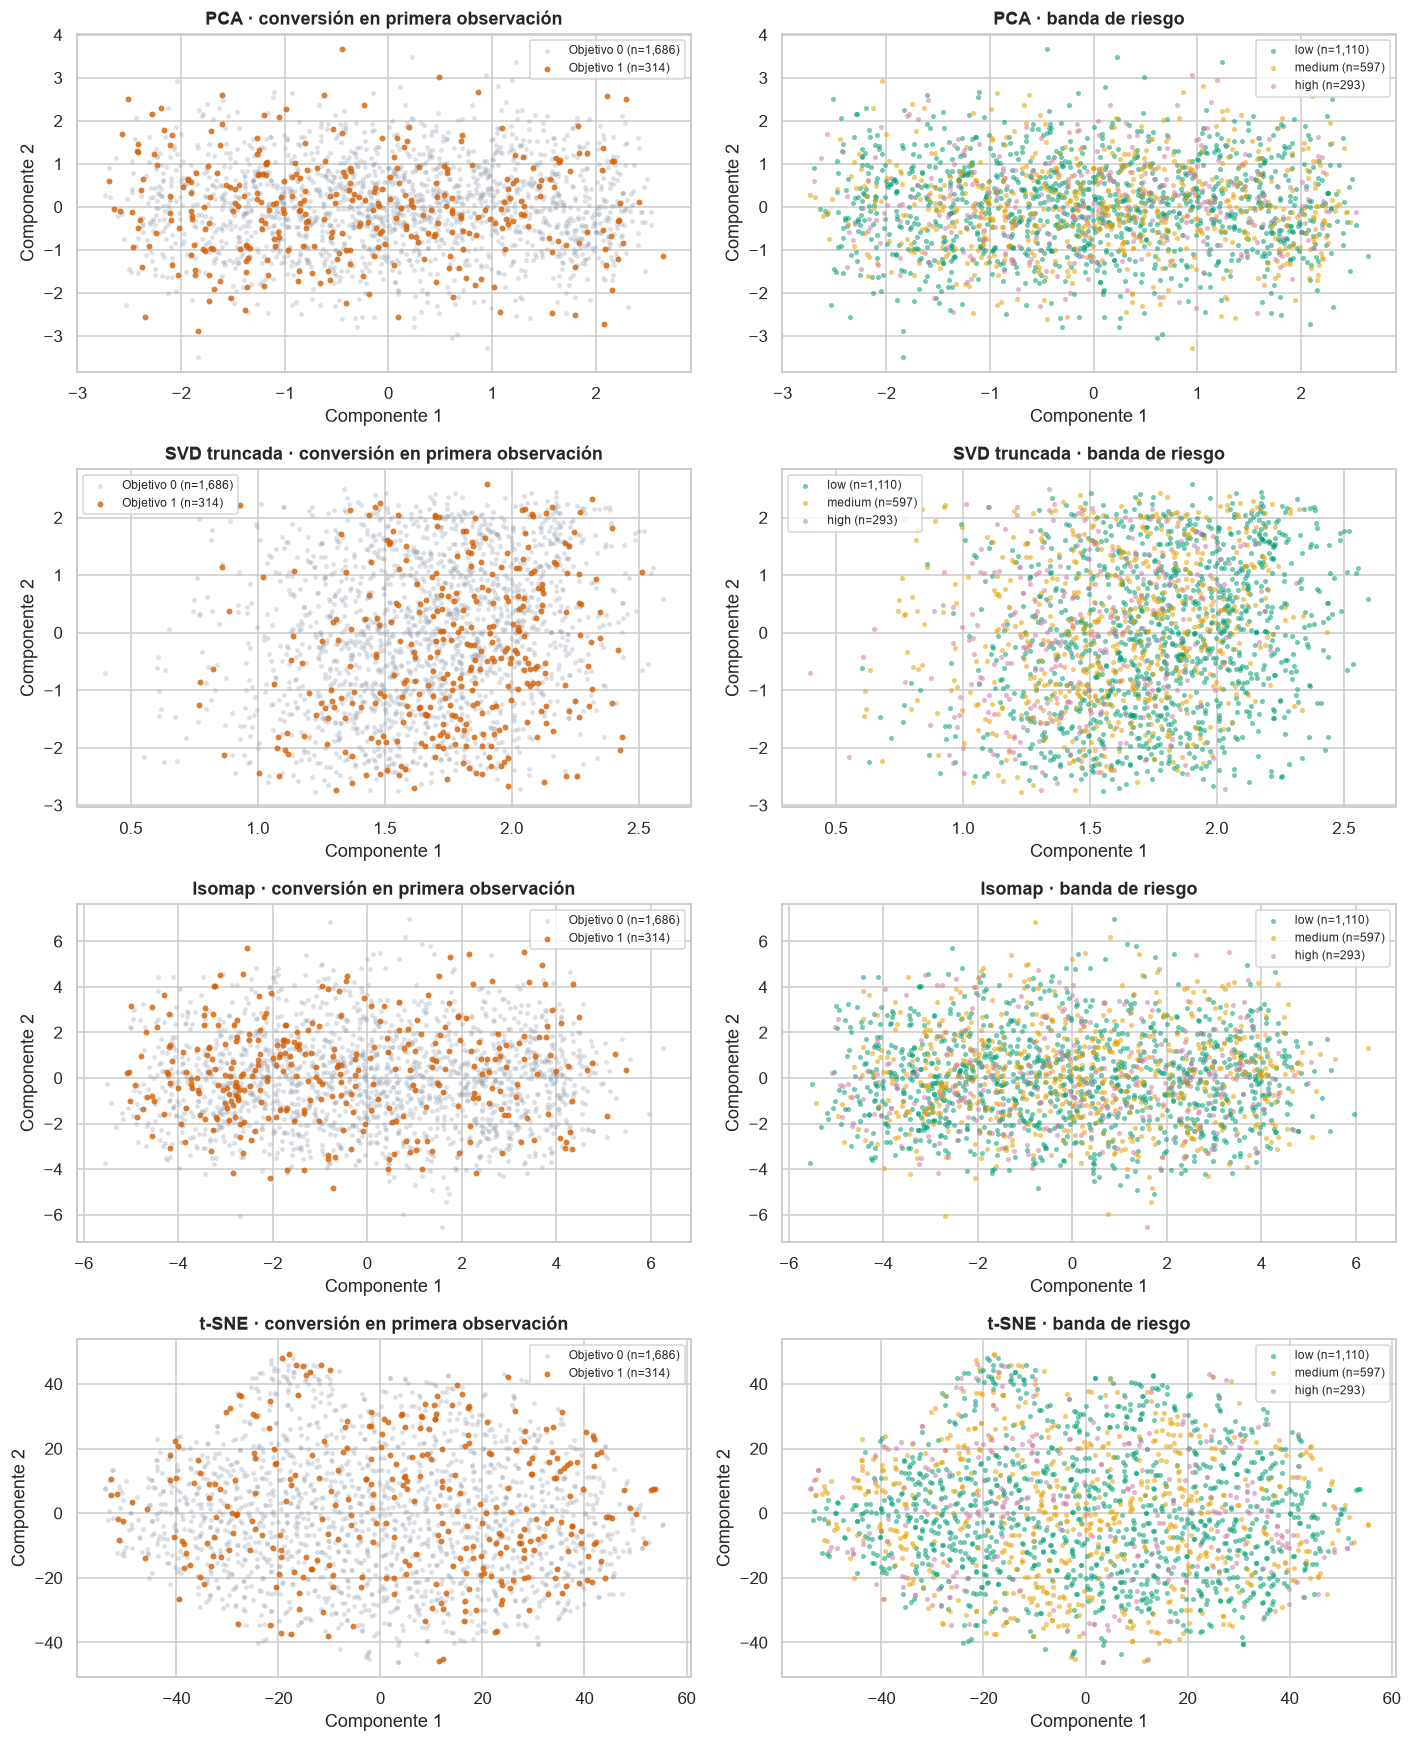

In [5]:
# Mismos puntos y colores. Las coordenadas son específicas de cada técnica y no se comparan entre filas.
fig, axes = plt.subplots(4, 2, figsize=(13, 16))
risk_colors = {'low': '#009E73', 'medium': '#E69F00', 'high': '#CC79A7'}
for row, (name, xy) in enumerate(maps.items()):
    ax = axes[row, 0]
    for label, color, alpha in [(0, '#8D99A6', .3), (1, '#D55E00', .8)]:
        mask = sample.objetivo.eq(label).to_numpy()
        ax.scatter(xy[mask, 0], xy[mask, 1], s=10 if label == 0 else 15, alpha=alpha,
                   color=color, linewidths=0, label=f'Objetivo {label} (n={mask.sum():,})')
    ax.set_title(f'{name} · conversión en primera observación')
    ax.legend(fontsize=8, loc='best')
    ax = axes[row, 1]
    for risk, color in risk_colors.items():
        mask = sample.banda_riesgo.eq(risk).to_numpy()
        ax.scatter(xy[mask, 0], xy[mask, 1], s=11, alpha=.55, color=color,
                   linewidths=0, label=f'{risk} (n={mask.sum():,})')
    ax.set_title(f'{name} · banda de riesgo')
    ax.legend(fontsize=8, loc='best')
    for ax in axes[row]:
        ax.set(xlabel='Componente 1', ylabel='Componente 2')
plt.tight_layout()
plt.savefig(OUT / 'comparacion_tecnicas.png', dpi=140)
plt.show()
# Guardar coordenadas permite auditar o reconstruir vistas sin recalcular Isomap/t-SNE.
coordinates = sample[['id_cliente', 'mes', 'objetivo', 'banda_riesgo']].copy()
for name, xy in maps.items():
    coordinates[name + '_1'], coordinates[name + '_2'] = xy[:, 0], xy[:, 1]
coordinates.to_csv(OUT / 'coordenadas_muestra.csv', index=False)

## ¿Cuánta información cabe en dos dimensiones?

`trustworthiness` mide conservación de vecindarios (más cerca de 1 es mejor), no calidad predictiva.
La varianza explicada solo tiene sentido para las técnicas lineales aquí reportadas. Para entender
cuántos ejes requiere el perfil, el siguiente PCA completo se ajusta a todas las primeras observaciones.

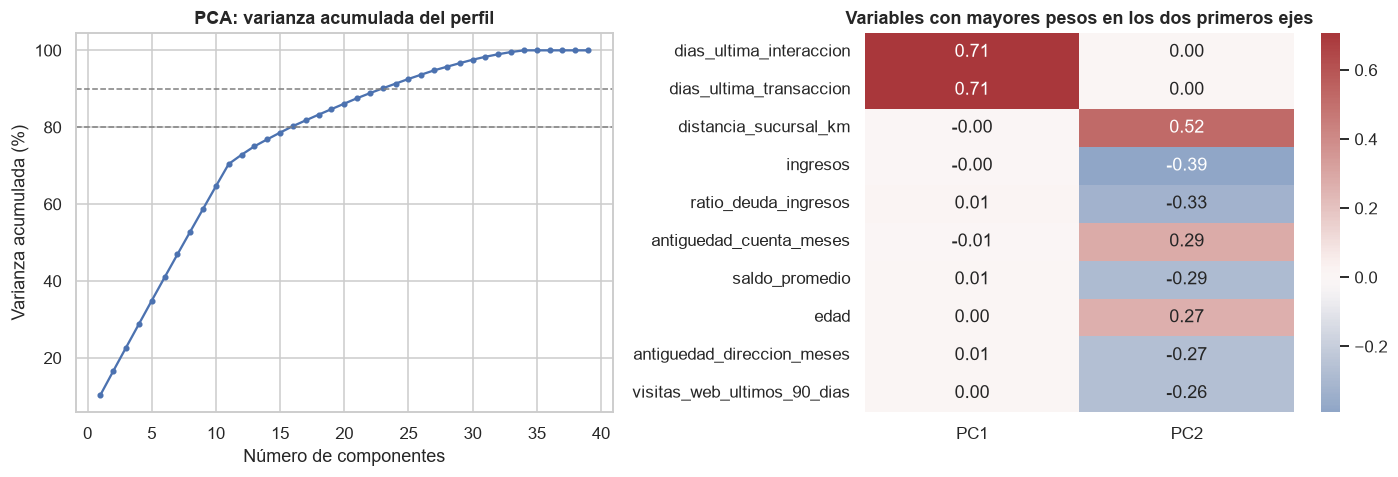

PCA poblacional: 2 ejes explican 16.5%; 80% requiere 16 y 90% requiere 23 ejes.


In [6]:
pca_full = PCA().fit(X_population)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n80 = int(np.searchsorted(cumulative, .8) + 1)
n90 = int(np.searchsorted(cumulative, .9) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(1, len(cumulative)+1), cumulative*100, marker='o', markersize=3)
for threshold in [80, 90]:
    axes[0].axhline(threshold, color='grey', linestyle='--', linewidth=1)
axes[0].set(title='PCA: varianza acumulada del perfil', xlabel='Número de componentes', ylabel='Varianza acumulada (%)')
loadings = pd.DataFrame(pca_full.components_[:2].T, index=prep.get_feature_names_out(), columns=['PC1', 'PC2'])
top = loadings.abs().max(axis=1).nlargest(10).index
sns.heatmap(loadings.loc[top], annot=True, fmt='.2f', center=0, cmap='vlag', ax=axes[1])
axes[1].set_title('Variables con mayores pesos en los dos primeros ejes')
axes[1].set_ylabel('')
plt.tight_layout(); plt.savefig(OUT / 'pca_varianza_pesos.png', dpi=140); plt.show()
print(f'PCA poblacional: 2 ejes explican {cumulative[1]:.1%}; 80% requiere {n80} y 90% requiere {n90} ejes.')
loadings.to_csv(OUT / 'pesos_pca.csv')

## Trayectorias de los mismos clientes

Para aislar cambios dentro de la persona elegimos 12 clientes presentes en los 11 meses de train.
Es una selección de trayectorias largas **solo para visualizar**: tiene sesgo de supervivencia y no
se usa para entrenar ni estimar tasas. En el panel izquierdo se conserva toda la información.
A la derecha se fija la interacción al valor inicial: ambos paneles usan exactamente el mismo PCA.
El movimiento que desaparece en esta comparación proviene exclusivamente de ese atributo.

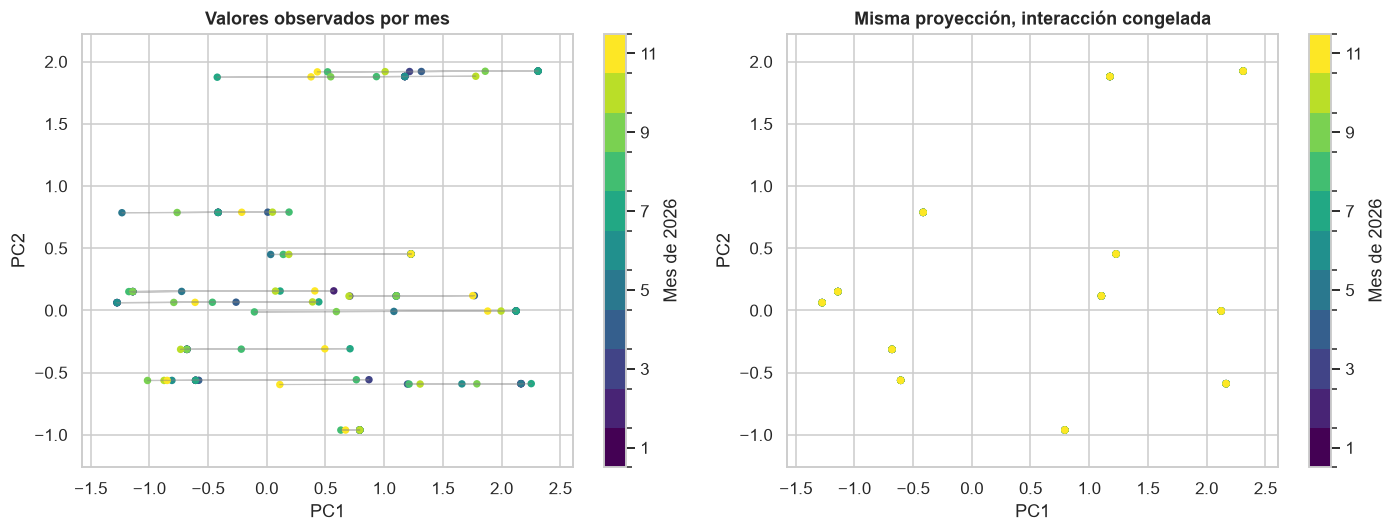

In [7]:
eligible = train.groupby('id_cliente').mes.nunique()
ids = np.random.default_rng(SEED).choice(eligible[eligible.eq(11)].index.to_numpy(), size=12, replace=False)
trajectory = train.loc[train.id_cliente.isin(ids)].copy()
actual = pca_full.transform(prep.transform(trajectory[features]))[:, :2]
frozen = trajectory.copy()
frozen['dias_ultima_interaccion'] = frozen.groupby('id_cliente').dias_ultima_interaccion.transform('first')
without_change = pca_full.transform(prep.transform(frozen[features]))[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
norm = BoundaryNorm(np.arange(.5, 12, 1), ncolors=256)
months = trajectory.mes.mod(100).to_numpy()
for ax, xy, title in zip(axes, [actual, without_change],
                        ['Valores observados por mes', 'Misma proyección, interacción congelada']):
    for client in ids:
        positions = np.flatnonzero(trajectory.id_cliente.to_numpy() == client)
        ax.plot(xy[positions, 0], xy[positions, 1], color='grey', alpha=.45, linewidth=.8)
    scatter = ax.scatter(xy[:, 0], xy[:, 1], c=months, cmap='viridis', norm=norm, s=24, linewidths=0)
    ax.set(title=title, xlabel='PC1', ylabel='PC2')
    plt.colorbar(scatter, ax=ax, ticks=[1, 3, 5, 7, 9, 11], label='Mes de 2026')
# Igualar límites es necesario para comparar desplazamientos.
for ax in axes:
    ax.set_xlim(actual[:, 0].min()-.3, actual[:, 0].max()+.3)
    ax.set_ylim(actual[:, 1].min()-.3, actual[:, 1].max()+.3)
plt.tight_layout(); plt.savefig(OUT / 'trayectorias_clientes.png', dpi=140); plt.show()
max_frozen_span = pd.DataFrame(without_change).groupby(trajectory.id_cliente.to_numpy()).agg(lambda s: s.max()-s.min()).to_numpy().max()
assert max_frozen_span < 1e-10

## Lectura de resultados

No confundir una nube con clases superpuestas con ausencia de señal en las 22 variables originales.
Tampoco interpretar islas de t-SNE como segmentos financieros ya validados: pueden reflejar categorías,
escala, densidad y parámetros. Colorear por riesgo es descriptivo porque riesgo entró a la reducción.
Las primeras observaciones mezclan cohortes; el objetivo mostrado es un evento mensual, no una etiqueta
permanente de persona. Los gráficos no usan el objetivo para decidir coordenadas o parámetros.

In [8]:
best_local = diagnostics.trustworthiness_k15.idxmax()
display(Markdown(f'''
- Dos componentes del PCA poblacional retienen **{cumulative[1]:.1%}** de la varianza; hacen falta
  **{n80} componentes para 80%**. Un mapa 2D necesariamente omite buena parte de la información.
- **{best_local}** obtiene la mayor conservación local medida en esta muestra
  (**{diagnostics.loc[best_local, 'trustworthiness_k15']:.3f}**, k=15). Esto no lo convierte en el mejor predictor.
- Las trayectorias colapsan a un punto por cliente al fijar `dias_ultima_interaccion`:
  el cambio mensual del perfil procede únicamente de esa variable. En una proyección lineal,
  cambios en una sola variable generan desplazamientos paralelos; no prueban una evolución de negocio.
- Los resultados dependen de muestra, codificación y parámetros. No se ha verificado estabilidad
  de clusters con otras semillas/perplejidades y no se proponen segmentos operativos a partir de estas figuras.
'''))


- Dos componentes del PCA poblacional retienen **16.5%** de la varianza; hacen falta
  **16 componentes para 80%**. Un mapa 2D necesariamente omite buena parte de la información.
- **t-SNE** obtiene la mayor conservación local medida en esta muestra
  (**0.876**, k=15). Esto no lo convierte en el mejor predictor.
- Las trayectorias colapsan a un punto por cliente al fijar `dias_ultima_interaccion`:
  el cambio mensual del perfil procede únicamente de esa variable. En una proyección lineal,
  cambios en una sola variable generan desplazamientos paralelos; no prueban una evolución de negocio.
- Los resultados dependen de muestra, codificación y parámetros. No se ha verificado estabilidad
  de clusters con otras semillas/perplejidades y no se proponen segmentos operativos a partir de estas figuras.
